In [2]:
!pip install mysql-connector-python pandas numpy

In [4]:
import mysql.connector
import pandas as pd
import numpy as np
from getpass import getpass

connection = mysql.connector.connect(
    host="localhost",
    port=3307,
    user="root",
    password=getpass("Enter MySQL password: "),
    database="agrisense"
)

print("MySQL connected successfully!")

Enter MySQL password:  ········


MySQL connected successfully!


In [8]:
query = """
SELECT state, district, crop, year, season, area, production
FROM agridata
WHERE state = 'Haryana'
AND district = 'Bhiwani';
"""

df = pd.read_sql(query, connection)

print("Data fetched from MySQL successfully!")
print("Total Bhiwani records:", len(df))

display(df.head())

C:\Users\DELL\AppData\Local\Temp\ipykernel_16088\3496486700.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, connection)


Data fetched from MySQL successfully!
Total Bhiwani records: 226


,state,district,crop,year,season,area,production
0,HARYANA,BHIWANI,Rice,1998-99,Kharif,7223,16000
1,HARYANA,BHIWANI,Rice,1999-00,Kharif,7317,17000
2,HARYANA,BHIWANI,Rice,2000-01,Kharif,8159,20000
3,HARYANA,BHIWANI,Rice,2001-02,Kharif,7422,21000
4,HARYANA,BHIWANI,Rice,2002-03,Kharif,6491,19000


In [9]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

Missing values:
state         0
district      0
crop          0
year          0
season        0
area          0
production    0
dtype: int64

Duplicate records: 0

Data types:
state         object
district      object
crop          object
year          object
season        object
area           int64
production     int64
dtype: object


In [10]:
total_records = pd.read_sql(
    "SELECT COUNT(*) AS total FROM agridata",
    connection
).iloc[0, 0]

bhiwani_records = len(df)

print("Complete database records:", total_records)
print("Bhiwani records extracted:", bhiwani_records)

print("Records excluded:",
      total_records - bhiwani_records)

Complete database records: 173069
Bhiwani records extracted: 226
Records excluded: 172843


C:\Users\DELL\AppData\Local\Temp\ipykernel_16088\3064200603.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  total_records = pd.read_sql(


In [11]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert numerical columns
df['area'] = pd.to_numeric(df['area'], errors='coerce')
df['production'] = pd.to_numeric(df['production'], errors='coerce')

# Remove rows with missing essential values
df = df.dropna(subset=['crop', 'year', 'season', 'area', 'production'])

# Remove invalid values
df = df[(df['area'] > 0) & (df['production'] >= 0)].copy()

print("Data cleaning completed!")
print("Records after cleaning:", len(df))

display(df.head())

Data cleaning completed!
Records after cleaning: 226


,state,district,crop,year,season,area,production
0,HARYANA,BHIWANI,Rice,1998-99,Kharif,7223,16000
1,HARYANA,BHIWANI,Rice,1999-00,Kharif,7317,17000
2,HARYANA,BHIWANI,Rice,2000-01,Kharif,8159,20000
3,HARYANA,BHIWANI,Rice,2001-02,Kharif,7422,21000
4,HARYANA,BHIWANI,Rice,2002-03,Kharif,6491,19000


In [12]:
# FEATURE ENGINEERING

# 1. Extract starting year from values like 1998-99
df['year_start'] = df['year'].astype(str).str[:4].astype(int)

# 2. Create decade
df['year_decade'] = (df['year_start'] // 10) * 10

# 3. Calculate production per unit area
df['calculated_yield'] = df['production'] / df['area']

# 4. Calculate crop's share of total area
df['crop_area_share'] = (
    df['area'] /
    df.groupby(['year', 'season'])['area'].transform('sum')
)

# 5. Calculate crop's share of total production
df['crop_production_share'] = (
    df['production'] /
    df.groupby(['year', 'season'])['production'].transform('sum')
)

print("Feature engineering completed!")

print("New shape:", df.shape)

display(df.head())

Feature engineering completed!
New shape: (226, 12)


,state,district,crop,year,season,area,production,year_start,year_decade,calculated_yield,crop_area_share,crop_production_share
0,HARYANA,BHIWANI,Rice,1998-99,Kharif,7223,16000,1998,1990,2.215146,0.026069,0.064516
1,HARYANA,BHIWANI,Rice,1999-00,Kharif,7317,17000,1999,1990,2.323357,0.028069,0.092492
2,HARYANA,BHIWANI,Rice,2000-01,Kharif,8159,20000,2000,2000,2.451281,0.031378,0.069857
3,HARYANA,BHIWANI,Rice,2001-02,Kharif,7422,21000,2001,2000,2.829426,0.028791,0.060746
4,HARYANA,BHIWANI,Rice,2002-03,Kharif,6491,19000,2002,2000,2.927130,0.023713,0.082215


In [13]:
# Check all columns
print("Final columns:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Display processed data
display(df.head(10))

Final columns:
['state', 'district', 'crop', 'year', 'season', 'area', 'production', 'year_start', 'year_decade', 'calculated_yield', 'crop_area_share', 'crop_production_share']

Missing values:
state                    0
district                 0
crop                     0
year                     0
season                   0
area                     0
production               0
year_start               0
year_decade              0
calculated_yield         0
crop_area_share          0
crop_production_share    0
dtype: int64

Data types:
state                     object
district                  object
crop                      object
year                      object
season                    object
area                       int64
production                 int64
year_start                 int64
year_decade                int64
calculated_yield         float64
crop_area_share          float64
crop_production_share    float64
dtype: object


,state,district,crop,year,season,area,production,year_start,year_decade,calculated_yield,crop_area_share,crop_production_share
0,HARYANA,BHIWANI,Rice,1998-99,Kharif,7223,16000,1998,1990,2.215146,0.026069,0.064516
1,HARYANA,BHIWANI,Rice,1999-00,Kharif,7317,17000,1999,1990,2.323357,0.028069,0.092492
2,HARYANA,BHIWANI,Rice,2000-01,Kharif,8159,20000,2000,2000,2.451281,0.031378,0.069857
3,HARYANA,BHIWANI,Rice,2001-02,Kharif,7422,21000,2001,2000,2.829426,0.028791,0.060746
4,HARYANA,BHIWANI,Rice,2002-03,Kharif,6491,19000,2002,2000,2.927130,0.023713,0.082215
5,HARYANA,BHIWANI,Rice,2003-04,Kharif,9890,23000,2003,2000,2.325581,0.036241,0.059065
6,HARYANA,BHIWANI,Rice,2004-05,Kharif,11412,14000,2004,2000,1.226779,0.040429,0.036678
7,HARYANA,BHIWANI,Rice,2005-06,Kharif,12526,25000,2005,2000,1.995849,0.040899,0.086866
8,HARYANA,BHIWANI,Rice,2006-07,Kharif,13666,26000,2006,2000,1.902532,0.053215,0.068224
9,HARYANA,BHIWANI,Rice,2007-08,Kharif,14818,40000,2007,2000,2.699420,0.062161,0.098304


In [14]:
# Save processed data as CSV
df.to_csv("bhiwani_processed_data.csv", index=False)

print("Processed data saved successfully!")

Processed data saved successfully!


In [15]:
# Load weather files directly from GitHub

live_url = "https://raw.githubusercontent.com/MansiDA09/AgriSense/main/data/live_weather.csv"

forecast_url = "https://raw.githubusercontent.com/MansiDA09/AgriSense/main/data/7_day_forecast.csv"

live_weather = pd.read_csv(live_url)
forecast_weather = pd.read_csv(forecast_url)

print("Live weather shape:", live_weather.shape)
print("Forecast weather shape:", forecast_weather.shape)

print("\nLive Weather Data:")
display(live_weather.head())

print("\n7-Day Forecast Data:")
display(forecast_weather.head())

Live weather shape: (1, 9)
Forecast weather shape: (7, 7)

Live Weather Data:


,city,state,updated_at,temperature_c,humidity_percent,rain_mm,wind_kmh,soil_temperature_c,soil_moisture
0,Bhiwani,Haryana,2026-11-25T11:00,22.9,42,0.0,3.8,26.0,0.209



7-Day Forecast Data:


,date,max_temp_c,min_temp_c,mean_temp_c,rainfall_mm,et0_mm,max_wind_kmh
0,2026-11-25,25.6,12.2,17.9,0.0,2.67,6.9
1,2026-11-26,25.8,10.8,17.5,0.0,2.65,7.1
2,2026-11-27,25.5,10.4,17.3,0.0,2.39,5.6
3,2026-11-28,24.5,10.8,17.2,0.0,2.41,6.5
4,2026-11-29,23.9,11.5,17.0,0.0,2.24,4.9


In [16]:
# AGRISENSE COMBINED REPORT

print("========== AGRISENSE REPORT ==========")

# 1. Historical Crop Data
print("\n1. HISTORICAL CROP DATA")
print("District:", df['district'].iloc[0])
print("Total crop records:", len(df))
print("Available crops:", df['crop'].nunique())

display(
    df[['crop', 'year', 'season', 'area',
        'production', 'calculated_yield']].head(10)
)

# 2. Current Weather
print("\n2. CURRENT WEATHER")
display(live_weather)

# 3. Seven-Day Weather Forecast
print("\n3. SEVEN-DAY WEATHER FORECAST")
display(forecast_weather)

print("\nAgriSense report generated successfully!")

========== AGRISENSE REPORT ==========

1. HISTORICAL CROP DATA
District: BHIWANI
Total crop records: 226
Available crops: 26


,crop,year,season,area,production,calculated_yield
0,Rice,1998-99,Kharif,7223,16000,2.215146
1,Rice,1999-00,Kharif,7317,17000,2.323357
2,Rice,2000-01,Kharif,8159,20000,2.451281
3,Rice,2001-02,Kharif,7422,21000,2.829426
4,Rice,2002-03,Kharif,6491,19000,2.927130
5,Rice,2003-04,Kharif,9890,23000,2.325581
6,Rice,2004-05,Kharif,11412,14000,1.226779
7,Rice,2005-06,Kharif,12526,25000,1.995849
8,Rice,2006-07,Kharif,13666,26000,1.902532
9,Rice,2007-08,Kharif,14818,40000,2.699420



2. CURRENT WEATHER


,city,state,updated_at,temperature_c,humidity_percent,rain_mm,wind_kmh,soil_temperature_c,soil_moisture
0,Bhiwani,Haryana,2026-11-25T11:00,22.9,42,0.0,3.8,26.0,0.209



3. SEVEN-DAY WEATHER FORECAST


,date,max_temp_c,min_temp_c,mean_temp_c,rainfall_mm,et0_mm,max_wind_kmh
0,2026-11-25,25.6,12.2,17.9,0.0,2.67,6.9
1,2026-11-26,25.8,10.8,17.5,0.0,2.65,7.1
2,2026-11-27,25.5,10.4,17.3,0.0,2.39,5.6
3,2026-11-28,24.5,10.8,17.2,0.0,2.41,6.5
4,2026-11-29,23.9,11.5,17.0,0.0,2.24,4.9
5,2026-11-30,23.5,10.5,16.2,0.0,2.26,5.1
6,2026-12-01,23.6,10.8,16.5,0.0,2.17,5.9



AgriSense report generated successfully!


In [17]:
# SELECT FEATURES FOR MACHINE LEARNING

ml_data = df[
    ['crop', 'season', 'year_start', 'area', 'calculated_yield']
].copy()

print("ML dataset created!")
print("Shape:", ml_data.shape)

display(ml_data.head())

ML dataset created!
Shape: (226, 5)


,crop,season,year_start,area,calculated_yield
0,Rice,Kharif,1998,7223,2.215146
1,Rice,Kharif,1999,7317,2.323357
2,Rice,Kharif,2000,8159,2.451281
3,Rice,Kharif,2001,7422,2.829426
4,Rice,Kharif,2002,6491,2.927130


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Separate input and target
X = ml_data[['crop', 'season', 'year_start', 'area']]
y = ml_data['calculated_yield']

# Convert categorical columns into numerical format
preprocessor = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(handle_unknown='ignore'),['crop', 'season'])], remainder='passthrough')

X_encoded = preprocessor.fit_transform(X)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print("Data preparation completed!")
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Data preparation completed!
Training records: 180
Testing records: 46


In [19]:
from sklearn.tree import DecisionTreeRegressor

# Create Decision Tree model
model = DecisionTreeRegressor(max_depth=5, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions on test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("-------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MODEL EVALUATION
-------------------------
MAE: 2.915220956080401
RMSE: 8.872033715583166
R2 Score: 0.7643255855569369


In [21]:
# Compare actual and predicted values
results = pd.DataFrame({'Actual Yield': y_test.values, 'Predicted Yield': y_pred})
results['Difference'] = (results['Actual Yield'] - results['Predicted Yield'])
display(results.head(15))

,Actual Yield,Predicted Yield,Difference
0,2.699420,1.277264,1.422156
1,2.680557,1.277264,1.403293
2,0.000000,0.087380,-0.087380
3,11.510791,16.520537,-5.009746
4,0.000000,0.087380,-0.087380
5,32.195750,71.942446,-39.746696
6,2.651454,1.277264,1.374191
7,0.895236,1.277264,-0.382028
8,1.954860,1.277264,0.677597
9,2.295800,1.277264,1.018536


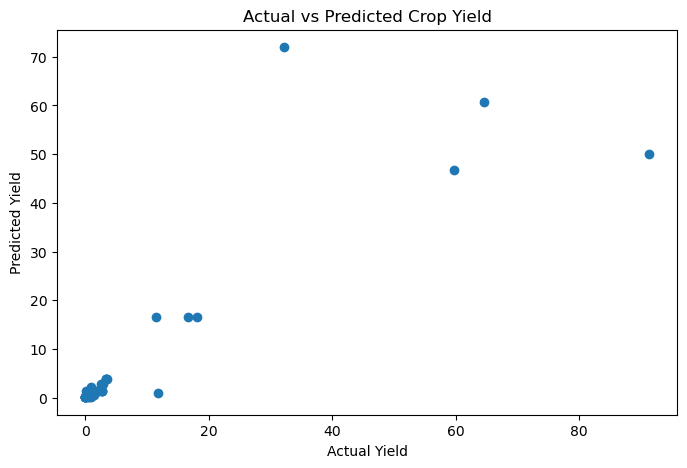

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Actual vs Predicted Crop Yield")

plt.show()

In [23]:
# Take the first row as a sample input
sample_input = X.iloc[[0]]

# Transform the input using the same preprocessing
sample_encoded = preprocessor.transform(sample_input)

# Predict yield
sample_prediction = model.predict(sample_encoded)

print("Sample Input:")
display(sample_input)

print("Predicted Yield:", sample_prediction[0])


Sample Input:


,crop,season,year_start,area
0,Rice,Kharif,1998,7223


Predicted Yield: 1.277263776402301


In [24]:
ml_results = ml_data.copy()

ml_results['predicted_yield'] = model.predict(
    preprocessor.transform(ml_data[['crop', 'season', 'year_start', 'area']])
)

ml_results.to_csv('agrisense_ml_results.csv', index=False)

print("ML results saved successfully!")
display(ml_results.head())

ML results saved successfully!


,crop,season,year_start,area,calculated_yield,predicted_yield
0,Rice,Kharif,1998,7223,2.215146,1.277264
1,Rice,Kharif,1999,7317,2.323357,1.277264
2,Rice,Kharif,2000,8159,2.451281,1.277264
3,Rice,Kharif,2001,7422,2.829426,1.277264
4,Rice,Kharif,2002,6491,2.927130,1.277264


In [25]:
new_data = pd.DataFrame({
    'crop': ['Wheat'],
    'season': ['Rabi'],
    'year_start': [2026],
    'area': [5000]
})

new_encoded = preprocessor.transform(new_data)

new_prediction = model.predict(new_encoded)

print("New Crop:", new_data['crop'][0])
print("Season:", new_data['season'][0])
print("Year:", new_data['year_start'][0])
print("Area:", new_data['area'][0])
print("Predicted Yield:", new_prediction[0])

New Crop: Wheat
Season: Rabi
Year: 2026
Area: 5000
Predicted Yield: 1.9398126520121854
